# Em quais recifes o estresse térmico que branqueia corais chega mais cedo e mais vezes, e dá para avisar com antecedência?

Corais branqueiam quando a água fica quente demais por tempo demais. A NOAA Coral Reef Watch mede isso por satélite
com o **Degree Heating Week (DHW)**: quanto a temperatura passou do máximo normal do lugar, acumulado em 12 semanas.
A decisão que este estudo informa é que recifes priorizar para monitoramento e resposta, e com quantas semanas de
antecedência um alerta simples é confiável.

O caminho: (1) refazer o DHW a partir da temperatura e conferir com o produto oficial; (2) medir ondas de calor
marinhas; (3) medir a tendência dos anos de estresse severo, com incerteza honesta; (4) testar a previsão contra a
persistência; (5) ordenar os recifes e medir a incerteza da ordem; (6) conferir com branqueamento observado em campo.

É análise de dado público, feita por um profissional de dados, não por um biólogo. Os números vêm de
`reports/resultados.json`; o método está em `src/corais_calor/` e é conferido em `tests/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from corais_calor import analise, dados, dhw, graficos, ondas

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 90)
r = json.loads(Path("reports/resultados.json").read_text(encoding="utf-8"))
base = dados.carregar()
series, diarias = analise.preparar(base)


def mostrar(figura):
    display(figura)
    plt.close(figura)


print("Coleta:", r["coleta"]["coletado_em"], "|", len(series), "recifes |", len(diarias), "recifes de referência")

Coleta: 2026-11-12 | 38 recifes | 6 recifes de referência


## 1. Os recifes e os dados

Um ponto por recife, em seis bacias. A coordenada de referência vem da Wikipedia ou do Wikidata; o pixel usado é o
de mar mais próximo na grade de 5 km da NOAA. Para todos os recifes há o DHW oficial e a temperatura (CoralTemp) numa
data a cada 7 dias desde 1985. Para seis **recifes de referência**, um por bacia, há também as séries diárias
completas (DHW oficial, CoralTemp e OISST): o servidor lê um arquivo por dia, e cada série diária de 40 anos leva de
8 a 20 minutos.

In [2]:
display(base.recifes[["nome", "regiao", "grupo", "lat", "lon", "lat_crw", "lon_crw", "km_crw", "mmm_noaa", "referencia"]])
display(pd.Series({k: v for k, v in r["coleta"]["crw"].items() if isinstance(v, dict)}).apply(pd.Series))

,nome,regiao,grupo,lat,lon,lat_crw,lon_crw,km_crw,mmm_noaa,referencia
slug,,,,,,,,,,
lizard,Lizard Island,"Grande Barreira de Corais, norte",Pacífico oeste,-14.669,145.459,-14.675,145.475,1.800,28.580,True
davies,Davies Reef,"Grande Barreira de Corais, centro",Pacífico oeste,-18.850,147.650,-18.875,147.625,3.800,28.400,False
heron,Heron Island,"Grande Barreira de Corais, sul",Pacífico oeste,-23.442,151.914,-23.425,151.925,2.200,27.120,False
osprey,Osprey Reef,Mar de Coral,Pacífico oeste,-13.908,146.615,-13.925,146.625,2.200,28.690,False
lord_howe,Lord Howe Island,Mar da Tasmânia (recife mais ao sul do mundo),Pacífico oeste,-31.554,159.085,-31.575,159.075,2.500,24.050,False
raja_ampat,Raja Ampat,"Triângulo de Coral, Indonésia",Pacífico oeste,-0.233,130.508,-0.275,130.525,5.000,28.970,False
tubbataha,Tubbataha,"Triângulo de Coral, Filipinas",Pacífico oeste,8.953,119.868,8.975,119.875,2.600,29.540,False
kimbe,Kimbe Bay,"Triângulo de Coral, Papua-Nova Guiné",Pacífico oeste,-5.167,150.500,-5.175,150.475,2.900,29.570,False
palau,Rock Islands,Palau,Pacífico oeste,7.250,134.350,7.225,134.325,3.900,29.220,False


,inicio,fim,datas,lacunas
semanal_sst,1985-01-06,2026-11-08,2184,32
semanal_dhw,1985-04-07,2026-11-08,2171,64
mensal,1985-01-31,2013-01-31,337,0
diario_sst,1985-01-01,2026-11-10,15284,0
diario_dhw,1985-04-01,2026-11-10,15183,0


## 2. O DHW foi entendido? Refazer e conferir

O DHW do dia é a soma, nos 84 dias anteriores, de quanto a temperatura passou do **MMM** (a média do mês mais quente
da climatologia), contando só os dias com 1 °C ou mais de excesso, dividida por 7. A climatologia da NOAA usa
1985-2012 e é recentrada pela tendência para 1988,286.

Quatro degraus de conferência, do mais controlado ao menos:

- **algoritmo**: temperatura e MMM oficiais; só a acumulação é refeita;
- **climatologia**: a mesma temperatura, com o MMM recalculado aqui a partir da média mensal;
- **outro produto**: temperatura do OISST (0,25°) e MMM calculado no próprio OISST;
- **semanal**: uma temperatura a cada 7 dias, em todos os recifes.

In [3]:
conf = r["conferencia_do_dhw"]
resumo = pd.DataFrame({k: {c: v for c, v in d.items() if not isinstance(v, dict)} for k, d in conf["resumo"].items()}).T
resumo["concordância DHW ≥ 4"] = [conf["resumo"][k]["dhw4"]["concordancia"] for k in resumo.index]
resumo["kappa DHW ≥ 4"] = [conf["resumo"][k]["dhw4"]["kappa"] for k in resumo.index]
display(resumo)
display(pd.Series({k: v for k, v in conf["mmm"].items() if k != "por_recife"}, name="MMM calculado menos MMM oficial (°C)").to_frame())
display(pd.DataFrame(conf["por_recife"]).set_index("nome"))

,recifes_ano,correlacao_do_maximo_anual,vies_do_maximo_anual,erro_absoluto_do_maximo_anual,erro_maximo_do_maximo_anual,concordância DHW ≥ 4,kappa DHW ≥ 4
algoritmo,249.000,1.000,-0.005,0.010,0.287,1.000,1.000
climatologia,249.000,1.000,-0.032,0.037,0.446,1.000,1.000
outro_produto,215.000,0.899,0.672,1.313,11.241,0.884,0.630
semanal,"1,568.000",0.984,0.025,0.424,3.850,0.961,0.874
amostragem_semanal,249.000,1.000,-0.014,0.014,1.290,1.000,1.000


,MMM calculado menos MMM oficial (°C)
recifes,38.000
diferenca_media,-0.000
diferenca_absoluta_media,0.003
diferenca_absoluta_maxima,0.006
dentro_de_0_05,38.000
sem_recentrar_diferenca_media,0.162
sem_recentrar_diferenca_absoluta_media,0.189


,slug,dias,erro_diario_algoritmo,erro_diario_maximo_algoritmo,erro_diario_climatologia,erro_diario_outro_produto,correlacao_diaria_outro_produto,mmm_noaa,mmm_coraltemp,mmm_oisst,dhw_maximo_noaa,dhw_maximo_algoritmo,dhw_maximo_outro_produto,sst_oisst_menos_coraltemp
nome,,,,,,,,,,,,,,
Lizard Island,lizard,15183,0.001,0.004,0.002,0.379,0.891,28.580,28.574,28.596,8.660,8.661,10.263,0.045
Atol de Kaafu (Malé),maldivas,15183,0.002,0.150,0.005,0.159,0.876,29.680,29.682,29.457,6.640,6.503,8.938,-0.007
Sir Abu Nu'ayr,sir_abu_nuayr,15183,0.000,0.004,0.005,0.267,0.575,33.660,33.665,33.558,7.590,7.591,8.364,-0.126
Kiritimati,kiritimati,15183,0.001,0.004,0.019,0.842,0.931,27.970,27.972,27.778,25.810,25.814,27.918,0.070
Looe Key,florida_keys,15183,0.001,0.004,0.012,0.263,0.967,29.640,29.645,29.448,17.970,17.971,20.034,-0.165
Abrolhos,abrolhos,15183,0.010,0.287,0.019,0.271,0.875,26.940,26.944,27.301,15.200,15.440,8.876,0.045


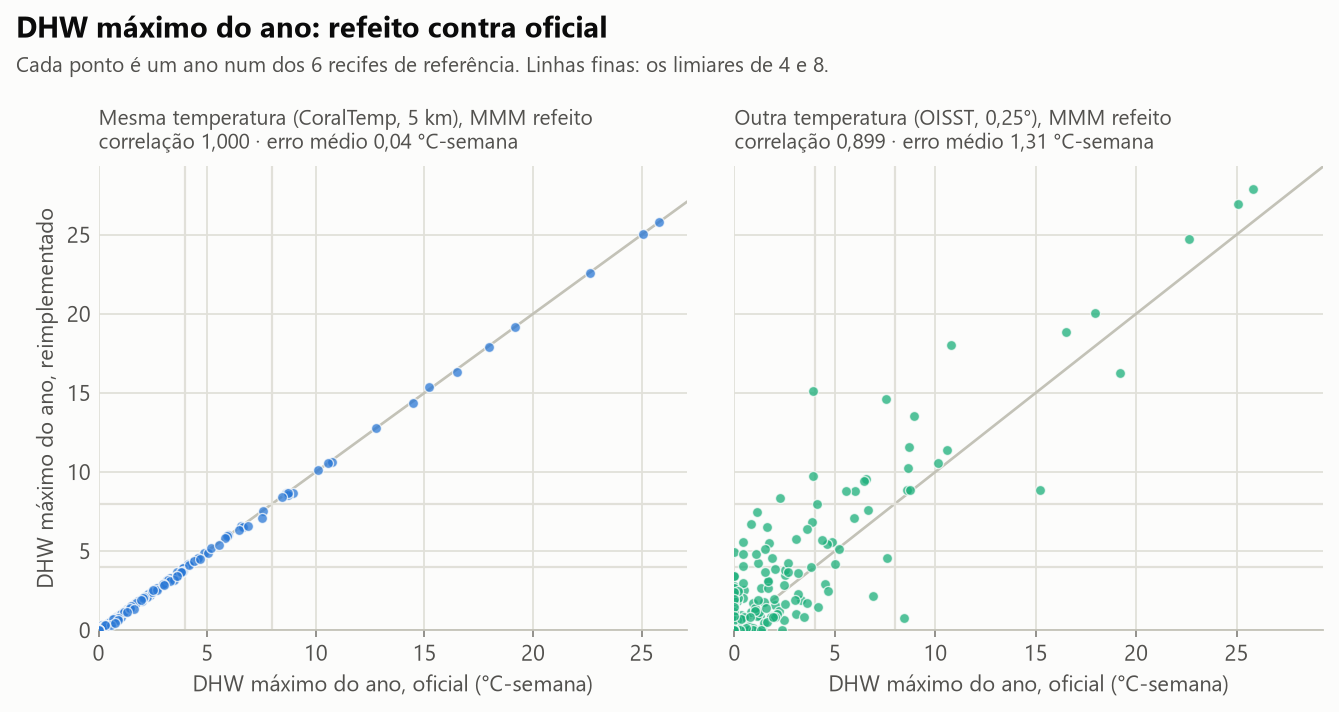

In [4]:
rc, ro = conf["resumo"]["climatologia"], conf["resumo"]["outro_produto"]
mostrar(graficos.conferencia_do_dhw(
    conf,
    "DHW máximo do ano: refeito contra oficial",
    f"Cada ponto é um ano num dos {len(diarias)} recifes de referência. Linhas finas: os limiares de 4 e 8.",
))

Um exemplo dia a dia: o recife de referência com o maior DHW da série. A linha do DHW refeito com a temperatura e
o MMM oficiais fica em cima da linha oficial.

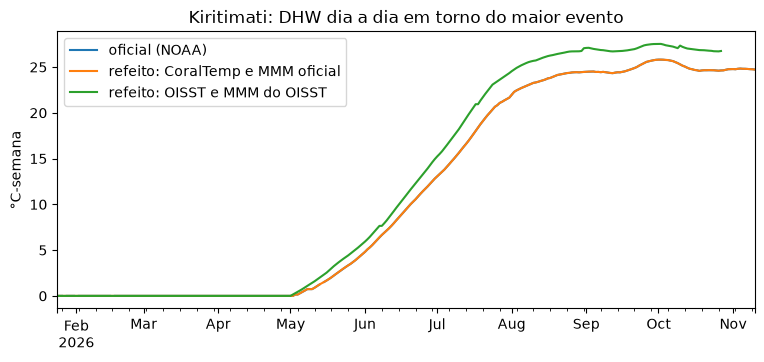

In [5]:
d = max(diarias, key=lambda x: np.nanmax(x.dhw_noaa))
pico = int(np.nanargmax(d.dhw_noaa))
trecho = slice(max(pico - 250, 0), pico + 200)
serie_oisst = pd.Series(d.sst_oisst, index=d.datas_oisst)
mmm_oisst = dhw.mmm(dhw.climatologia_mensal(d.datas_oisst, d.sst_oisst))
comparacao = pd.DataFrame({
    "oficial (NOAA)": d.dhw_noaa,
    "refeito: CoralTemp e MMM oficial": dhw.dhw(d.sst, d.serie.mmm_noaa),
    "refeito: OISST e MMM do OISST": pd.Series(dhw.dhw(d.sst_oisst, mmm_oisst), index=d.datas_oisst).reindex(d.datas).to_numpy(),
}, index=pd.DatetimeIndex(d.datas))
eixo = comparacao.iloc[trecho].plot(figsize=(9, 3.6), title=f"{d.nome}: DHW dia a dia em torno do maior evento")
eixo.set_ylabel("°C-semana")
plt.show()

## 3. Ondas de calor marinhas (Hobday et al. 2016)

Definição: cinco dias ou mais acima do percentil 90 do dia do ano, medido em 1983-2012 no OISST diário. Aqui só nos
recifes de referência, que são os que têm a série diária. O limiar é fixo; com o mar aquecendo, mais dias passam dele.
É o que a definição mede, e não separa tendência de variabilidade.

In [6]:
oc = r["ondas_de_calor"]
display(pd.DataFrame(oc["por_decada"]).set_index("periodo")[["eventos_por_ano", "dias_por_ano", "duracao_media", "intensidade_maxima_media"]])
linhas = {x["nome"]: {dec["periodo"]: dec["dias_por_ano"] for dec in x["decadas"]} | {"dias a mais por década": x["dias_a_mais_por_decada"], "maior evento": x["maior_evento"]["inicio"], "duração (dias)": x["maior_evento"]["duracao"]} for x in oc["por_recife"]}
display(pd.DataFrame(linhas).T)

,eventos_por_ano,dias_por_ano,duracao_media,intensidade_maxima_media
periodo,,,,
1985-1994,2.150,21.350,10.101,1.657
1995-2004,1.983,24.783,12.832,1.517
2005-2014,2.117,23.833,11.748,1.447
2015-2024,4.567,96.800,23.643,1.537


,1985-1994,1995-2004,2005-2014,2015-2024,dias a mais por década,maior evento,duração (dias)
Lizard Island,18.200,28.800,31.700,117.600,33.052,2016-02-14,174
Atol de Kaafu (Malé),23.600,17.800,14.200,110.900,23.909,2016-01-28,116
Sir Abu Nu'ayr,17.400,26.100,18.800,68.900,15.512,2026-08-03,100
Kiritimati,41.500,30.800,9.000,62.600,0.192,2015-05-13,326
Looe Key,10.300,25.500,44.200,137.500,40.413,2023-05-17,109
Abrolhos,17.100,19.700,25.100,83.300,20.336,2024-04-10,182


## 4. A tendência dos anos de estresse severo

Para cada recife e cada ano de estresse (a janela de 12 meses em torno do mês mais quente), o máximo do DHW oficial.
Um ano conta como "de alerta" se o máximo passa de 4 °C-semana e como "severo" se passa de 8.

No conjunto, a fração de recifes atingidos por ano entra numa regressão binomial sobre o ano. O intervalo vem de um
bootstrap que sorteia **anos inteiros em blocos de 4**: os recifes de um mesmo ano não são independentes (um El Niño
atinge muitos de uma vez), e sortear a linha do ano inteira preserva isso.

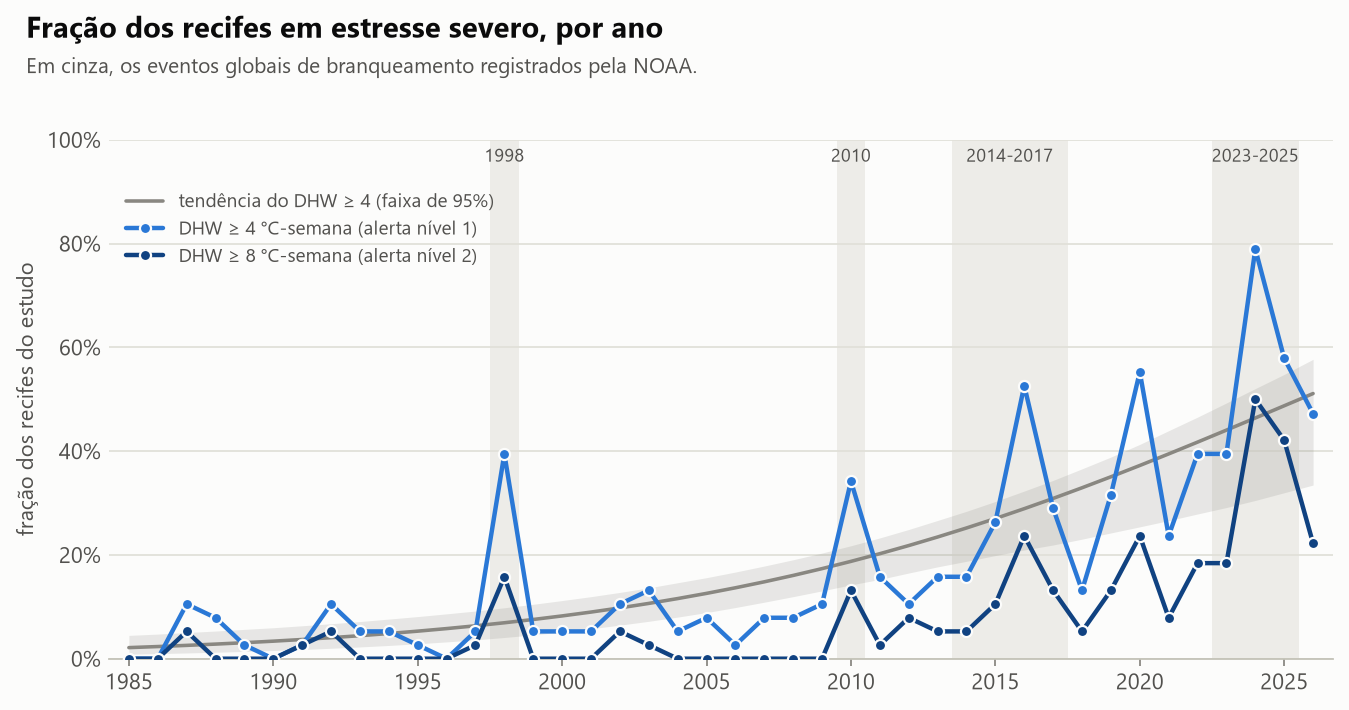

dhw4 | razão de chances por década: 2.57 [1.84, 3.37] | superdispersão: 3.9


,recifes,com_algum_evento,inclinacao_positiva,p_bruto_menor_que_5,p_bh_menor_que_5,p_holm_menor_que_5,piorou_de_antes_para_depois,melhorou_de_antes_para_depois,sem_evento_antes_e_com_evento_depois,sem_evento_em_toda_a_serie
dhw4,38,37,36,24,16,8,32,2,13,1


dhw8 | razão de chances por década: 3.25 [1.93, 5.4] | superdispersão: 3.3


,recifes,com_algum_evento,inclinacao_positiva,p_bruto_menor_que_5,p_bh_menor_que_5,p_holm_menor_que_5,piorou_de_antes_para_depois,melhorou_de_antes_para_depois,sem_evento_antes_e_com_evento_depois,sem_evento_em_toda_a_serie
dhw8,38,30,30,18,8,2,26,1,22,8


In [7]:
t = r["tendencias"]
mostrar(graficos.fracao_por_ano(t, analise.EVENTOS_GLOBAIS, "Fração dos recifes em estresse severo, por ano", "Em cinza, os eventos globais de branqueamento registrados pela NOAA."))
for chave in ("dhw4", "dhw8"):
    c = t[chave]["conjunto"]
    print(chave, "| razão de chances por década:", round(c["razao_de_chances_por_decada"], 2), [round(v, 2) for v in c["razao_de_chances_ic"]], "| superdispersão:", round(c["superdispersao"], 1))
    display(pd.Series(t[chave]["contagem"], name=chave).to_frame().T)

Os eventos globais de branqueamento que a NOAA registra (1998, 2010, 2014-2017 e 2023-2024) aparecem nas séries?

In [8]:
g = r["eventos_globais"]["dhw4"]
display(pd.DataFrame(g["por_evento"]).T)
display(pd.DataFrame(g["dez_piores_anos"]))
print("média nos anos de evento global:", round(g["media_nos_anos_de_evento"], 3), "| nos outros anos:", round(g["media_nos_outros_anos"], 3))

,anos,fracao_maxima,fracao_media
1998,[1998],0.395,0.395
2010,[2010],0.342,0.342
2014-2017,"[2014, 2015, 2016, 2017]",0.526,0.309
2023-2025,"[2023, 2024, 2025]",0.789,0.588


,ano,fracao,evento_global
0,2024,0.789,True
1,2025,0.579,True
2,2020,0.553,False
3,2016,0.526,True
4,2026,0.472,False
5,1998,0.395,True
6,2022,0.395,False
7,2023,0.395,True
8,2010,0.342,True
9,2019,0.316,False


média nos anos de evento global: 0.415 | nos outros anos: 0.117


### Intervalo de retorno, antes e depois de 2005

O intervalo de retorno é o número médio de anos entre dois anos de alerta: o inverso da frequência.

recifes  retorno 1985-2004  \
limiar recorte                                                    
dhw4   todos                              38             14.115   
       Pacífico oeste                     11             15.071   
       Índico                              8             11.692   
       Mar Vermelho e golfo Pérsico        3             20.000   
       Pacífico central e leste            7              8.000   
       Caribe e Atlântico Norte            4             20.000   
       Atlântico Sul                       5             95.000   
dhw8   todos                              38             48.933   
       Pacífico oeste                     11            211.000   
       Índico                              8             76.000   
       Mar Vermelho e golfo Pérsico        3                NaN   
       Pacífico central e leste            7             12.364   
       Caribe e Atlântico Norte            4                NaN   
       Atlântico Sul                       5             95.000   

                                     retorno 2005-2024  razão de frequência  \
limiar recorte                                                                
dhw4   todos                                     3.858                3.659   
       Pacífico oeste                            3.438                4.384   
       Índico                                    5.161                2.265   
       Mar Vermelho e golfo Pérsico              3.333                6.000   
       Pacífico central e leste                  5.385                1.486   
       Caribe e Atlântico Norte                  2.000               10.000   
       Atlântico Sul                             5.556               17.100   
dhw8   todos                                     9.157                5.344   
       Pacífico oeste                           10.476               20.141   
       Índico                                   17.778                4.275   
       Mar Vermelho e golfo Pérsico              5.455                  NaN   
       Pacífico central e leste                  9.333                1.325   
       Caribe e Atlântico Norte                  4.706                  NaN   
       Atlântico Sul                            10.000                9.500   

                                                  IC 95%  
limiar recorte                                            
dhw4   todos                          [1.82705, 6.32262]  
       Pacífico oeste                  [1.85808, 9.6254]  
       Índico                         [1.11528, 3.53864]  
       Mar Vermelho e golfo Pérsico          [2.0, 22.0]  
       Pacífico central e leste        [0.73675, 2.4375]  
       Caribe e Atlântico Norte             [4.25, 23.0]  
       Atlântico Sul                         [2.5, 26.0]  
dhw8   todos                         [1.86364, 11.11146]  
       Pacífico oeste                        [3.0, 31.0]  
       Índico                                [1.0, 12.0]  
       Mar Vermelho e golfo Pérsico                 None  
       Pacífico central e leste        [0.5464, 2.71429]  
       Caribe e Atlântico Norte                     None  
       Atlântico Sul                     [0.60417, 16.0]

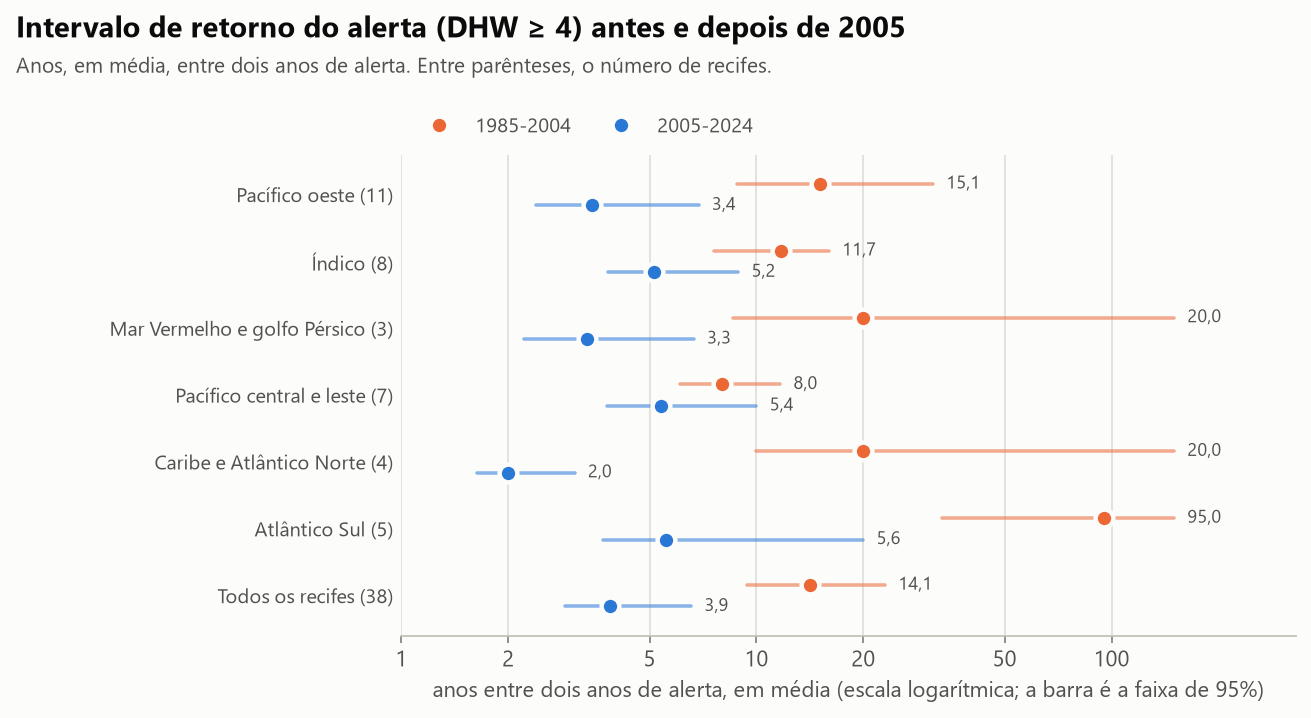

In [9]:
linhas = []
for chave in ("dhw4", "dhw8"):
    for nome, x in t[chave]["retorno"].items():
        linhas.append({"limiar": chave, "recorte": nome, "recifes": x["recifes"], "retorno 1985-2004": x["antes"]["retorno"], "retorno 2005-2024": x["depois"]["retorno"], "razão de frequência": x["razao_de_frequencia"], "IC 95%": x["razao_ic"]})
display(pd.DataFrame(linhas).set_index(["limiar", "recorte"]))
mostrar(graficos.retorno_por_regiao(t, "dhw4", "Intervalo de retorno do alerta (DHW ≥ 4) antes e depois de 2005", "Anos, em média, entre dois anos de alerta. Entre parênteses, o número de recifes."))

### Recife a recife, com correção para múltiplas comparações

Com cerca de 40 anos e poucos eventos por recife, a tendência individual é incerta. O valor-p vem de uma permutação
em blocos; `p_bh` é o valor ajustado por Benjamini-Hochberg entre os recifes com algum evento.

In [10]:
por_recife = pd.DataFrame(t["dhw4"]["por_recife"])
por_recife["décadas"] = por_recife["por_decada"].apply(lambda v: " | ".join(str(x) for x in v))
display(por_recife.set_index("nome")[["grupo", "eventos", "décadas", "primeiro_ano", "inclinacao", "ic", "p", "p_bh"]].sort_values("p"))

,grupo,eventos,décadas,primeiro_ano,inclinacao,ic,p,p_bh
nome,,,,,,,,
Ras Mohammed,Mar Vermelho e golfo Pérsico,16,0 | 2 | 4 | 8,"1,998.000",1.712,"[1.14539, 2.7615]",0.000,0.004
Bermudas,Caribe e Atlântico Norte,16,0 | 2 | 3 | 9,"1,998.000",2.144,"[1.26672, 4.10118]",0.000,0.004
Kimbe Bay,Pacífico oeste,10,0 | 0 | 3 | 6,"2,010.000",2.097,"[1.45092, 3.64614]",0.000,0.005
Nosy Be,Índico,7,0 | 0 | 1 | 4,"2,010.000",2.301,"[1.05026, 4.13061]",0.001,0.005
Glover's Reef,Caribe e Atlântico Norte,11,0 | 1 | 2 | 6,"1,998.000",1.433,"[0.54916, 2.62143]",0.001,0.005
Looe Key,Caribe e Atlântico Norte,11,0 | 0 | 4 | 5,"2,005.000",1.669,"[0.76785, 3.13133]",0.001,0.005
Raja Ampat,Pacífico oeste,8,0 | 0 | 0 | 6,"2,017.000",4.268,"[0.0, 5.58981]",0.001,0.005
Lizard Island,Pacífico oeste,7,0 | 0 | 0 | 5,"2,016.000",2.863,"[0.0, 4.30696]",0.001,0.006
Curaçao,Caribe e Atlântico Norte,13,0 | 1 | 5 | 6,"2,003.000",1.523,"[0.75615, 2.91078]",0.002,0.008


## 5. Dá para avisar com antecedência?

O alvo: na data-alvo, dentro da estação quente, o DHW do recife estará em 4 ou mais? Previsões emitidas 4, 8 e 12
semanas antes. Treino com alvos até 2010; teste de 2011 em diante.

- **Persistência da anomalia**: a anomalia de hoje continua; projeta-se a temperatura e calcula-se o DHW.
- **Climatologia**: a frequência do alerta naquele recife e época do ano, no treino.
- **Modelo simples**: logística com a anomalia, a tendência de 4 semanas, o DHW de hoje, a posição na estação e o
  Niño 3.4 (com um coeficiente por bacia).

Brier  \
semanas método                                                              
4       Persistência da anomalia (sim ou não)                       0.056   
        Persistência da anomalia, calibrada                         0.054   
        Climatologia do recife e da época                           0.133   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4  0.046   
        Modelo mais a projeção de persistência                      0.040   
        Modelo sem o Niño 3.4                                       0.046   
8       Persistência da anomalia (sim ou não)                       0.096   
        Persistência da anomalia, calibrada                         0.089   
        Climatologia do recife e da época                           0.133   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4  0.088   
        Modelo mais a projeção de persistência                      0.078   
        Modelo sem o Niño 3.4                                       0.088   
12      Persistência da anomalia (sim ou não)                       0.138   
        Persistência da anomalia, calibrada                         0.113   
        Climatologia do recife e da época                           0.132   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4  0.119   
        Modelo mais a projeção de persistência                      0.109   
        Modelo sem o Niño 3.4                                       0.118   

                                                                    IC inf.  \
semanas método                                                                
4       Persistência da anomalia (sim ou não)                         0.046   
        Persistência da anomalia, calibrada                           0.041   
        Climatologia do recife e da época                             0.090   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4    0.035   
        Modelo mais a projeção de persistência                        0.031   
        Modelo sem o Niño 3.4                                         0.035   
8       Persistência da anomalia (sim ou não)                         0.079   
        Persistência da anomalia, calibrada                           0.066   
        Climatologia do recife e da época                             0.090   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4    0.065   
        Modelo mais a projeção de persistência                        0.059   
        Modelo sem o Niño 3.4                                         0.064   
12      Persistência da anomalia (sim ou não)                         0.113   
        Persistência da anomalia, calibrada                           0.082   
        Climatologia do recife e da época                             0.090   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4    0.086   
        Modelo mais a projeção de persistência                        0.080   
        Modelo sem o Niño 3.4                                         0.084   

                                                                    IC sup.  \
semanas método                                                                
4       Persistência da anomalia (sim ou não)                         0.068   
        Persistência da anomalia, calibrada                           0.069   
        Climatologia do recife e da época                             0.183   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4    0.059   
        Modelo mais a projeção de persistência                        0.051   
        Modelo sem o Niño 3.4                                         0.059   
8       Persistência da anomalia (sim ou não)                         0.114   
        Persistência da anomalia, calibrada                           0.116   
        Climatologia do recife e da época                             0.183   
        Modelo: anomalia, tendência, DHW atual, estação e Niño 3.4    0.113  

,4,8,12
linhas,15036,15104,15188
eventos,2240,2246,2253
taxa_de_eventos,0.149,0.149,0.148
anos,"[2011, 2026]","[2011, 2026]","[2011, 2026]"
linhas_fora_do_alerta,13028,13617,14307
eventos_fora_do_alerta,720,1385,1885


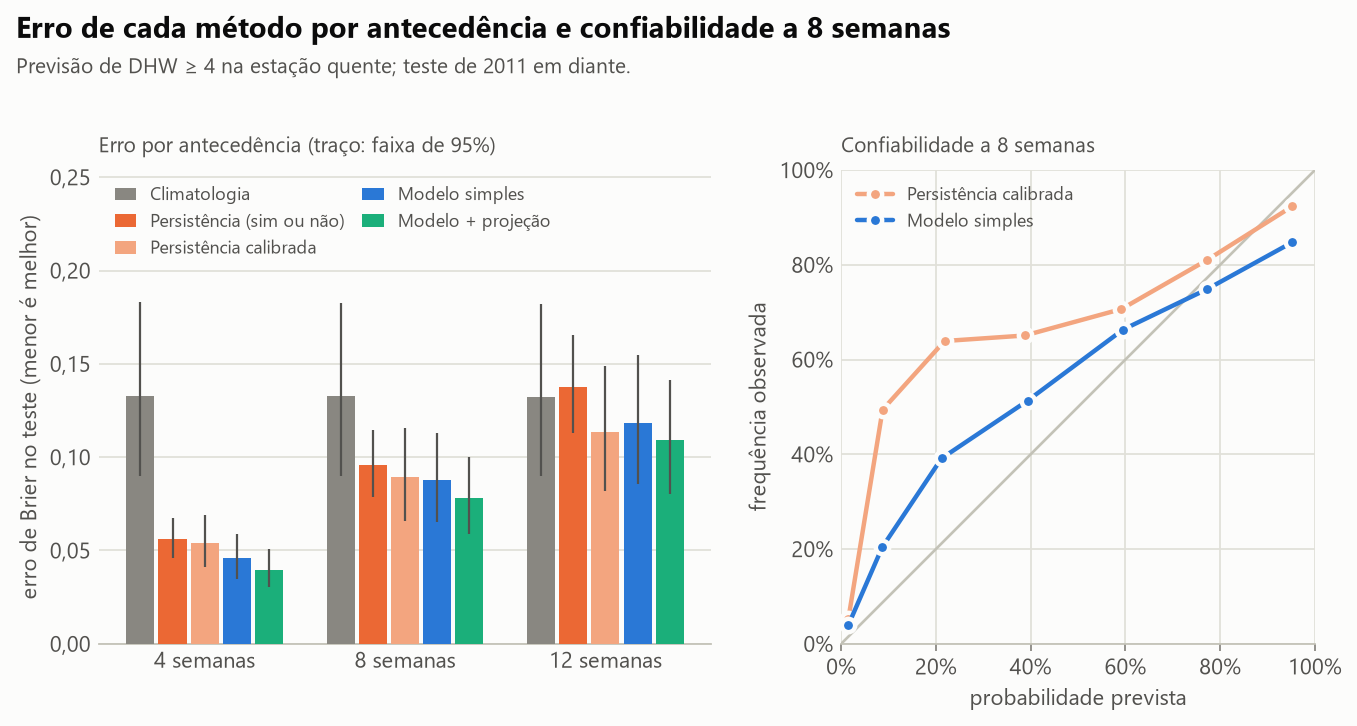

In [11]:
p = r["previsao"]
linhas = []
for semanas, x in p["antecedencias"].items():
    for nome, m in x["metodos"].items():
        linhas.append({"semanas": int(semanas), "método": m["rotulo"], "Brier": m["brier"], "IC inf.": m["brier_ic"][0], "IC sup.": m["brier_ic"][1], "ganho sobre a climatologia": m["ganho_sobre_climatologia"], "AUC": m["auc"], "Brier (fora do alerta)": m["brier_fora_do_alerta"], "AUC (fora do alerta)": m["auc_fora_do_alerta"], "alertas confirmados": m["alerta"]["precisao"], "eventos avisados": m["alerta"]["avisados"]})
display(pd.DataFrame(linhas).set_index(["semanas", "método"]))
display(pd.DataFrame({s: x["teste"] for s, x in p["antecedencias"].items()}))
mostrar(graficos.previsao_por_antecedencia(p, "Erro de cada método por antecedência e confiabilidade a 8 semanas", "Previsão de DHW ≥ 4 na estação quente; teste de 2011 em diante."))

In [12]:
linhas = []
for semanas, x in p["antecedencias"].items():
    for nome, c in x["comparacoes"].items():
        linhas.append({"semanas": int(semanas), "comparação (diferença de Brier)": nome.replace("_menos_", " − "), "diferença": c["diferenca"], "IC inf.": c["ic"][0], "IC sup.": c["ic"][1], "P(primeiro melhor)": c["prob_primeiro_melhor"]})
display(pd.DataFrame(linhas).set_index(["semanas", "comparação (diferença de Brier)"]))
display(pd.DataFrame({s: x["coeficientes"]["modelo"] for s, x in p["antecedencias"].items()}))

diferença  IC inf.  \
semanas comparação (diferença de Brier)                                    
4       modelo − persistencia_calibrada                  -0.008   -0.012   
        modelo − persistencia                            -0.010   -0.015   
        modelo_com_projecao − persistencia_calibrada     -0.014   -0.019   
        modelo − modelo_sem_nino                         -0.000   -0.001   
        persistencia_calibrada − climatologia            -0.079   -0.117   
        persistencia_calibrada − persistencia            -0.002   -0.007   
8       modelo − persistencia_calibrada                  -0.002   -0.004   
        modelo − persistencia                            -0.008   -0.015   
        modelo_com_projecao − persistencia_calibrada     -0.011   -0.017   
        modelo − modelo_sem_nino                         -0.000   -0.002   
        persistencia_calibrada − climatologia            -0.043   -0.069   
        persistencia_calibrada − persistencia            -0.006   -0.014   
12      modelo − persistencia_calibrada                   0.005    0.002   
        modelo − persistencia                            -0.019   -0.031   
        modelo_com_projecao − persistencia_calibrada     -0.004   -0.010   
        modelo − modelo_sem_nino                          0.001   -0.002   
        persistencia_calibrada − climatologia            -0.019   -0.037   
        persistencia_calibrada − persistencia            -0.024   -0.034   

                                                      IC sup.  \
semanas comparação (diferença de Brier)                         
4       modelo − persistencia_calibrada                -0.005   
        modelo − persistencia                          -0.005   
        modelo_com_projecao − persistencia_calibrada   -0.010   
        modelo − modelo_sem_nino                        0.001   
        persistencia_calibrada − climatologia          -0.048   
        persistencia_calibrada − persistencia           0.003   
8       modelo − persistencia_calibrada                 0.001   
        modelo − persistencia                          -0.001   
        modelo_com_projecao − persistencia_calibrada   -0.006   
        modelo − modelo_sem_nino                        0.002   
        persistencia_calibrada − climatologia          -0.024   
        persistencia_calibrada − persistencia           0.003   
12      modelo − persistencia_calibrada                 0.009   
        modelo − persistencia                          -0.007   
        modelo_com_projecao − persistencia_calibrada   -0.000   
        modelo − modelo_sem_nino                        0.004   
        persistencia_calibrada − climatologia          -0.006   
        persistencia_calibrada − persistencia          -0.014   

                                                      P(primeiro melhor)  
semanas comparação (diferença de Brier)                                   
4       modelo − persistencia_calibrada                            1.000  
        modelo − persistencia                                      1.000  
        modelo_com_projecao − persistencia_calibrada               1.000  
        modelo − modelo_sem_nino                                   0.631  
        persistencia_calibrada − climatologia                      1.000  
        persistencia_calibrada − persistencia                      0.792  
8       modelo − persistencia_calibrada                            0.874  
        modelo − persistencia                                      0.986  
        modelo_com_projecao − persistencia_calibrada               1.000  
        modelo − modelo_sem_nino                                   0.515  
        persistencia_calibrada − climatologia                      1.000  
        persistencia_calibrada − persistencia                      0.925  
12      modelo − persistencia_calibrada                            0.001  
        modelo − persistencia                                      0.999  
        modelo_com_projecao − pe

,4,8,12
constante,-6.595,-4.940,-4.162
anomalia,1.564,1.320,1.005
tendencia,-0.391,-0.078,-0.187
dhw_atual,1.697,0.702,0.182
sazonal,1.632,0.873,0.337
nino: Pacífico oeste,0.212,0.230,0.275
nino: Índico,0.189,0.121,0.079
nino: Mar Vermelho e golfo Pérsico,-0.059,-0.092,-0.070
nino: Pacífico central e leste,0.057,0.094,0.184
nino: Caribe e Atlântico Norte,-0.113,-0.091,-0.120


## 6. Ranking de exposição e a incerteza do ranking

Exposição em 2005-2024: fração de anos com DHW de 4 ou mais, somada à fração com 8 ou mais. A incerteza do posto vem
de sortear de novo os anos (em blocos, os mesmos para todos os recifes). **Exposição térmica não é branqueamento**:
profundidade, turbidez, aclimatação e espécie mudam o resultado.

,nome,grupo,anos_dhw4,anos_dhw8,dhw_maximo,prob_terco_mais_exposto,posto_ic
posto,,,,,,,
1,Ilha Darwin,Pacífico central e leste,13,8,15.560,1.000,"[1, 3]"
2,Ras Mohammed,Mar Vermelho e golfo Pérsico,12,7,25.270,1.000,"[1, 5]"
3,Bermudas,Caribe e Atlântico Norte,12,5,12.620,0.999,"[1, 6]"
4,Curaçao,Caribe e Atlântico Norte,11,5,22.150,0.953,"[1, 13]"
5,Glover's Reef,Caribe e Atlântico Norte,8,5,17.410,0.871,"[4, 15]"
6,Kimbe Bay,Pacífico oeste,9,4,15.710,0.997,"[4, 10]"
7,Osprey Reef,Pacífico oeste,7,5,12.080,0.945,"[4, 14]"
8,Scott Reef,Índico,9,2,15.890,0.925,"[3, 14]"
9,Looe Key,Caribe e Atlântico Norte,9,2,17.880,0.588,"[7, 20]"


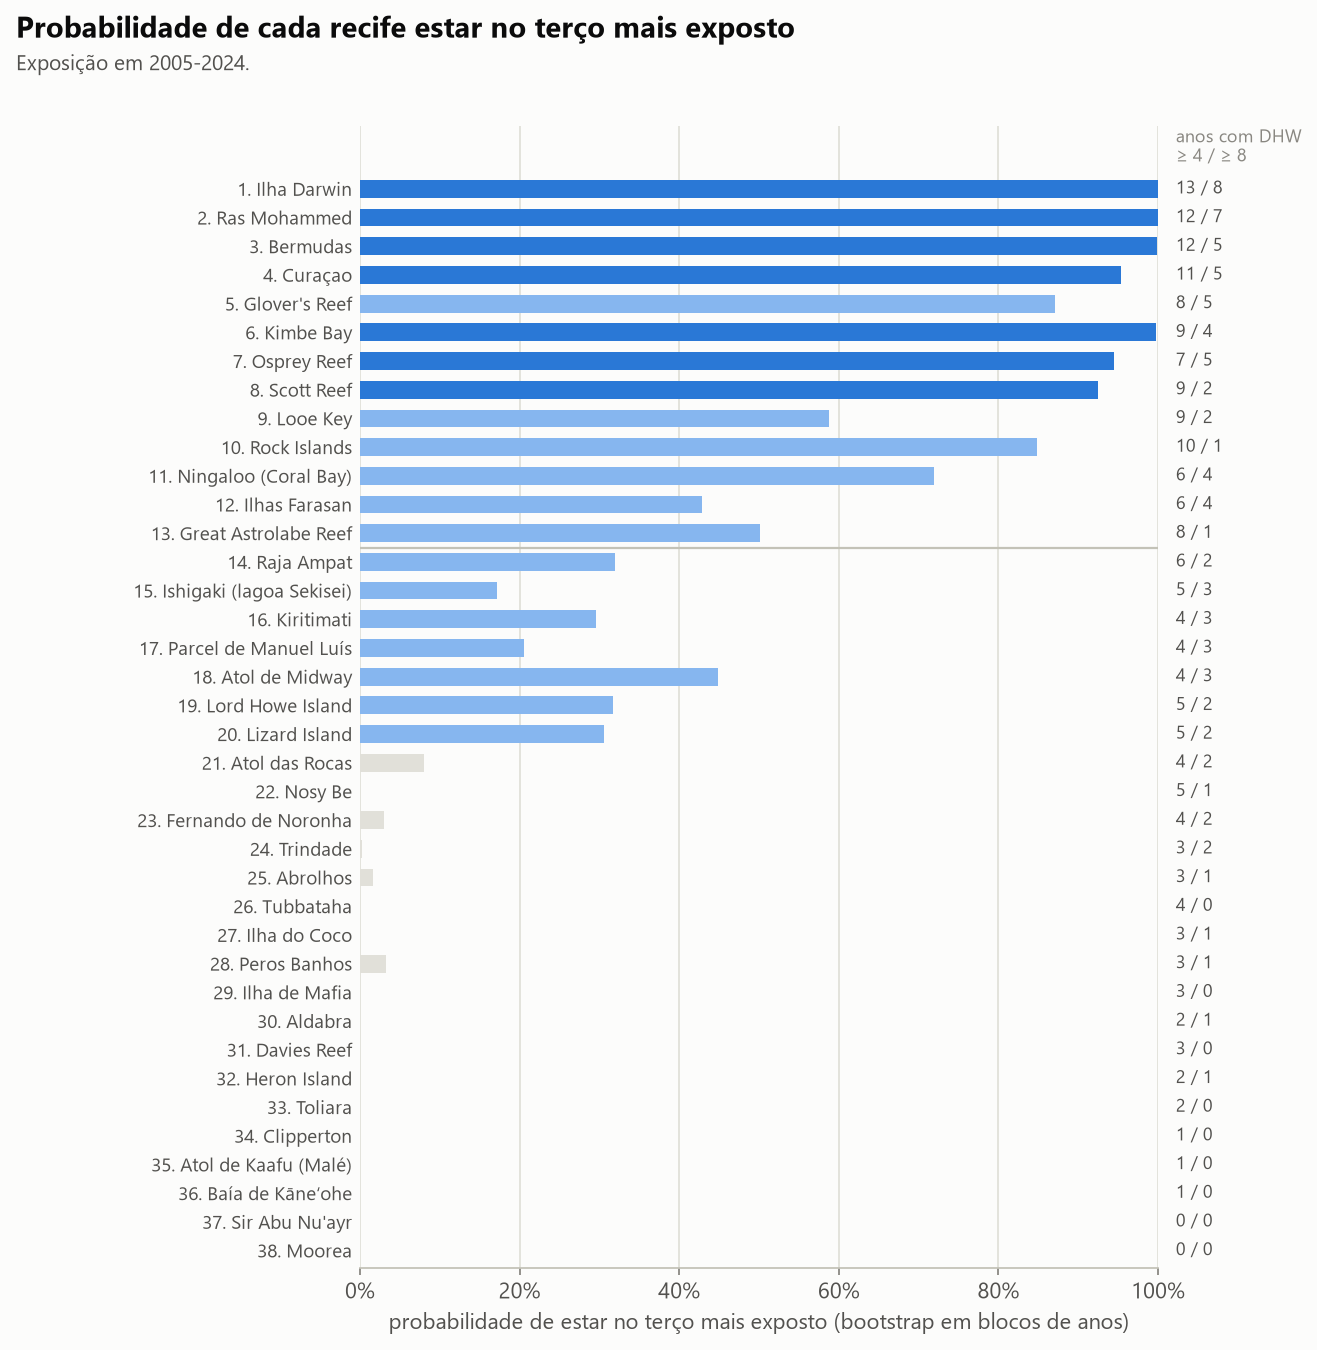

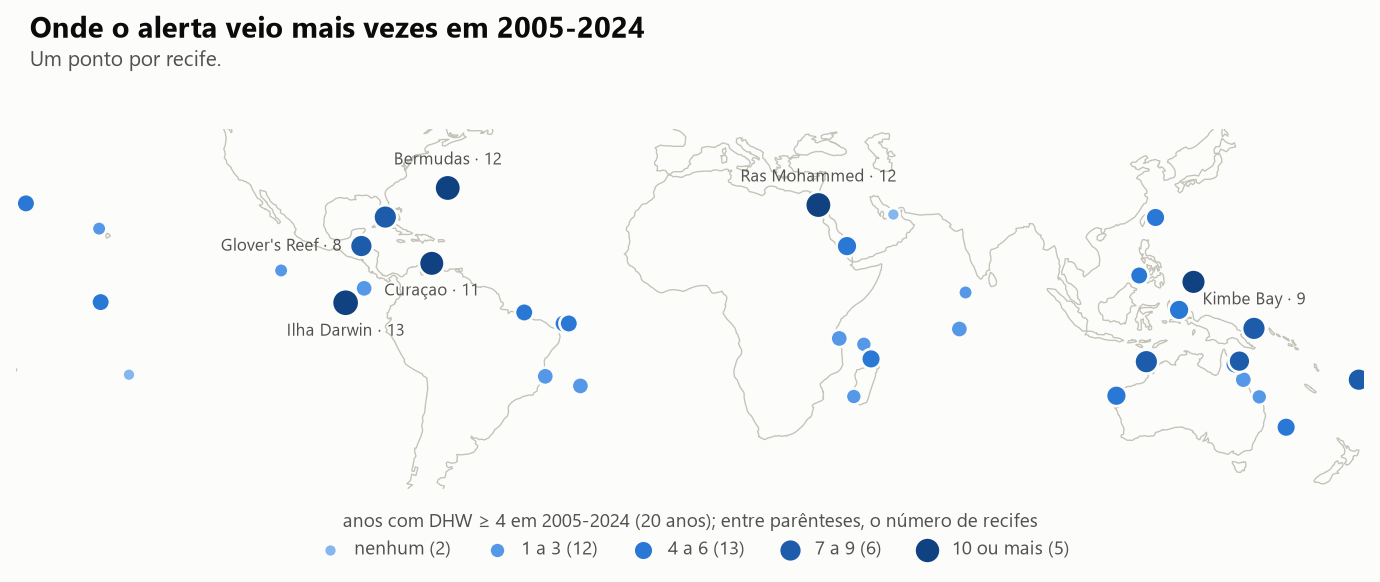

In [13]:
k = r["ranking"]
display(pd.DataFrame(k["por_recife"]).set_index("posto")[["nome", "grupo", "anos_dhw4", "anos_dhw8", "dhw_maximo", "prob_terco_mais_exposto", "posto_ic"]])
mostrar(graficos.ranking_com_incerteza(k, "Probabilidade de cada recife estar no terço mais exposto", "Exposição em 2005-2024."))
mostrar(graficos.mapa_de_exposicao(base.recifes, base.costa, k, [x["slug"] for x in k["por_recife"][:6]], "Onde o alerta veio mais vezes em 2005-2024", "Um ponto por recife."))

## 7. O satélite contra o que se viu em campo

A base de van Woesik e Burkepile (2022) reúne levantamentos de branqueamento com data e local. Para cada levantamento
a até 100 km de um recife do estudo, o estresse é o maior DHW oficial do ponto nas 12 semanas anteriores.

In [14]:
bo = r["branqueamento_observado"]
print({c: bo[c] for c in ("linhas", "levantamentos", "recifes", "recifes_ano", "anos")}, bo["por_fonte"])
display(pd.DataFrame(bo["por_faixa"]).set_index("faixa_dhw"))
display(pd.DataFrame(bo["limiares"]).T)
print(bo.get("so_reef_check"))

{'linhas': 1350, 'levantamentos': 2857, 'recifes': 31, 'recifes_ano': 243, 'anos': [1987, 2020]} {'AGRRA': 99, 'Donner': 668, 'FRRP': 874, 'Kumagai': 176, 'McClanahan': 29, 'Reef_Check': 991, 'Safaie': 20}


,linhas,percentual_medio,fracao_com_10_ou_mais,fracao_com_30_ou_mais
faixa_dhw,,,,
0,658,4.966,0.108,0.056
0 a 4,453,10.761,0.276,0.143
4 a 8,200,24.356,0.555,0.325
8 ou mais,39,31.786,0.615,0.513


,com_branqueamento,auc,auc_ic,sensibilidade_dhw4,especificidade_dhw4,branqueamento_sem_estresse
10,331,0.735,"[0.6495, 0.79937]",0.408,0.898,0.214
30,187,0.732,"[0.62757, 0.8047]",0.455,0.868,0.198


{'linhas': 786, 'com_10_ou_mais': 40, 'auc_10': 0.58768, 'auc_10_ic': [0.4677, 0.71497]}


## 8. O que levar daqui

- Refazer o índice oficial é o primeiro teste: com a mesma temperatura e o mesmo MMM, a acumulação reproduz o produto
  da NOAA; as diferenças que sobram vêm da climatologia e, sobretudo, do produto de temperatura.
- No conjunto dos recifes a tendência é clara; recife a recife, 40 anos com poucos eventos sustentam menos, e a
  correção para múltiplas comparações tira parte das tendências "significativas".
- A persistência da anomalia é uma linha de base forte. O modelo simples ganha dela com 4 semanas, empata com 8 e
  perde com 12; o índice Niño 3.4 não acrescentou nada mensurável.
- O ranking tem um topo e um fundo firmes e um meio indefinido. E o topo inclui lugares conhecidos por corais
  tolerantes ao calor: exposição térmica não é branqueamento.
- Com levantamentos de rotina (Reef Check), o DHW do ponto do recife quase não separa quem branqueou de quem não.
- O README lista onde o estudo falha e o que faltaria para isto virar contribuição científica.